# Predicting Significant Pipeline Incidents from Operator Reports

## Business understanding

**Problem.** Pipeline operators and PHMSA need to decide where to inspect first. A *significant* incident (a fatality, a hospitalised injury, at least $50,000 in damage, a large release, or a fire or explosion) is costly and dangerous. If inspections go to the operators most likely to have one, serious incidents can be prevented instead of investigated afterwards.

**Question.** Using each operator's annual report and incident history up to year *t*, can we rank operators by their chance of a significant incident in year *t+1*, and which factors drive that ranking?

**Who would use this.** An inspection-planning team at PHMSA, or an operator's risk team, deciding which operators to inspect when the budget covers only a fixed number of operator-years.

**How the design changed from the original proposal.** The first plan was incident-level severity prediction using pipe age, material, pressure and cause. The public annual reports don't hold those details for each incident, so the unit of analysis is the **operator-year**: one row per operator per year, with its pipe, volume and incident history. Pipe age is estimated from Part E, which splits pipe miles by installation decade.

**How success is measured.** Significant incidents are rare (about 12% of operator-years), so accuracy is misleading: always predicting "no" scores about 89%. The main metric is **PR-AUC**, and precision and recall at a fixed inspection budget are reported, because they match the decision about how many operators can be inspected.

## 1. Imports and path setup

In [234]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import precision_recall_curve
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold,cross_val_predict
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import SequentialFeatureSelector


In [235]:
# All paths in one place so they are easy to change
PROJECT_DIR = Path.cwd().parent  # Parent of notebooks directory
BASE = PROJECT_DIR
ANNUAL_DIR = BASE / "data" / "raw" / "annual"
INCIDENT_FILE = BASE / "data" / "raw" / "incident" / "hl2010toPresent.xlsx"
PROCESSED_DIR = BASE / "data" / "processed"#reproducible data
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
KEYS = ["OPERATOR_ID", "REPORT_YEAR"]

#Readable names for the charts
READABLE = {
    "PARTCONCRUDE": "Onshore volume: crude oil",
    "PARTCONHVL": "Onshore volume: HVL",
    "PARTCONCO2": "Onshore volume: CO2",
    "PARTCONRPP": "Onshore volume: refined products",
    "PARTCONETHANOL": "Onshore volume: ethanol",
    "PARTCOFFCRUDE": "Offshore volume: crude oil",
    "PARTCOFFHVL": "Offshore volume: HVL",
    "PARTCOFFRPP": "Offshore volume: refined products",
    "PARTCOFFETHANOL": "Offshore volume: ethanol",
    "PARTCOFFCO2": "Offshore volume: CO2",
    "PARTBHCAONSHORE": "High-consequence-area miles, onshore",
    "PARTBHCAOFFSHORE": "High-consequence-area miles, offshore",
}

## 2. Load annual reports from 2010-2025

Each yearly workbook has one row per operator *per commodity report*. We standardize column names and operator IDs, then stack all years.

In [236]:
#Data loading 

frames = []
for year in range(2010, 2026):
    tmp = pd.read_excel(
        ANNUAL_DIR / f"annual_hazardous_liquid_{year}.xlsx",
        sheet_name="HL AR Part A to E",
        header=2,
    )
    tmp.columns = tmp.columns.astype(str).str.strip()
    tmp = tmp[tmp["REPORT_YEAR"].notna()].copy()   # drop empty rows
    tmp["SOURCE_YEAR"] = year
    frames.append(tmp)



In [237]:
#Stdandardize operator IDs to match across years

def standardize_id(series):
    """Operator IDs as zero-padded 5-character strings so merges match."""
    return (pd.to_numeric(series, errors="coerce")
              .astype("Int64").astype("string").str.zfill(5))

annual_core = pd.concat(frames, ignore_index=True, sort=False)
annual_core["REPORT_YEAR"] = pd.to_numeric(annual_core["REPORT_YEAR"], errors="coerce").astype("Int64")
annual_core["OPERATOR_ID"] = standardize_id(annual_core["OPERATOR_ID"])
annual_core = annual_core.dropna(subset=["OPERATOR_ID", "REPORT_YEAR"]).copy()

annual_core.to_csv(PROCESSED_DIR / "annual_core_2010_2025.csv", index=False)
print("Combined shape:", annual_core.shape)
annual_core.groupby("REPORT_YEAR").size().to_frame("report_rows").T

Combined shape: (10358, 89)


REPORT_YEAR,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
report_rows,492,502,530,567,593,615,663,682,693,702,713,722,719,722,718,725


## 3. Build the operator-year table

Right now each row is one *report*. An operator that carries more than one commodity files more than one report in the same year, so the same operator and year can show up twice.

My model needs exactly one row per operator per year, so I will:
1. Check how many operator-years are repeated
2. Add up the miles for each operator-year
3. Collect basic operator info (name, number of reports, interstate/intrastate)
4. Turn commodity types into 1/0 columns
5. Combine everything and check there are no duplicates

In [238]:
# How many rows repeat an operator and year?
keys = ["OPERATOR_ID", "REPORT_YEAR"]
print("Repeated operator-years:", annual_core.duplicated(keys).sum())

Repeated operator-years: 2223


In [239]:
# 3 Add up the mileage columns (Part B to E hold the pipeline miles)
mile_cols = [c for c in annual_core.columns if c.startswith(("PARTB", "PARTC", "PARTD", "PARTE"))]

for c in mile_cols:
    annual_core[c] = pd.to_numeric(annual_core[c], errors="coerce")

# min_count=1 keeps a blank as blank when ALL of an operator's reports are blank
miles = annual_core.groupby(keys, as_index=False)[mile_cols].sum(min_count=1)
print("Mileage table:", miles.shape)

Mileage table: (8135, 72)


In [240]:
#  Basic operator info, one row per operator-year
details = annual_core.groupby(keys, as_index=False).agg(
    OPERATOR_NAME=("PARTA2NAMEOFCOMP", "first"),
    REPORT_COUNT=("REPORT_NUMBER", "nunique"),
    COMMODITY_COUNT=("PARTA5COMMODITY", "nunique"),
    HAS_INTERSTATE=("PARTA7INTER", lambda v: int(v.notna().any())),
    HAS_INTRASTATE=("PARTA7INTRA", lambda v: int(v.notna().any())),
)
details.head(5)

,OPERATOR_ID,REPORT_YEAR,OPERATOR_NAME,REPORT_COUNT,COMMODITY_COUNT,HAS_INTERSTATE,HAS_INTRASTATE
0,00117,2019,AIR PRODUCTS & CHEMICALS INC,1,1,0,1
1,00117,2020,AIR PRODUCTS & CHEMICALS INC,1,1,0,1
2,00117,2021,AIR PRODUCTS & CHEMICALS INC,1,1,0,1
3,00117,2022,AIR PRODUCTS & CHEMICALS INC,1,1,0,1
4,00117,2023,AIR PRODUCTS & CHEMICALS INC,1,1,0,1


In [241]:
#  One 1/0 column per commodity, then combine an operator's reports with max():Multi-hot encoding of commodities per operator-year
dummies = pd.get_dummies(annual_core["PARTA5COMMODITY"], prefix="COMMODITY", dtype=int)
commodity_flags = pd.concat([annual_core[keys], dummies], axis=1).groupby(keys, as_index=False).max()
commodity_flags.head(5)

,OPERATOR_ID,REPORT_YEAR,COMMODITY_CO2,COMMODITY_Crude Oil,COMMODITY_Fuel Grade Ethanol (dedicated system),COMMODITY_HVL,COMMODITY_Refined and/or Petroleum Product (non-HVL)
0,00117,2019,1,0,0,0,0
1,00117,2020,1,0,0,0,0
2,00117,2021,1,0,0,0,0
3,00117,2022,1,0,0,0,0
4,00117,2023,1,0,0,0,0


In [242]:
# Put the three pieces together and check
operator_year = (details.merge(miles, on=keys, how="left")
                     .merge(commodity_flags, on=keys, how="left"))
operator_year["REPORT_YEAR"] = operator_year["REPORT_YEAR"].astype(int)

print("Operator-year shape:", operator_year.shape)
print("Duplicate operator-years:", operator_year.duplicated(keys).sum())   # must be 0

Operator-year shape: (8135, 82)
Duplicate operator-years: 0


**Result:** 10,358 report rows contained 2,223 repeated operator-years. After combining, the table has 8,135 rows (one per operator per year) and 0 duplicates.

## 4. Loading incidents File and checking completeness

We read the incident workbook once and keep only the columns we need. Before building the label, we check that each incident year looks complete. If the most recent year is only partly reported, operators would look safer than they really were in that year.

In [243]:
incidents_raw = pd.read_excel(INCIDENT_FILE, sheet_name="hl2010toPresent", engine="openpyxl")
incidents_raw.columns = incidents_raw.columns.astype(str).str.strip()

In [244]:
#keeping only the columns we need for the analysis
needed_cols = ["OPERATOR_ID", "IYEAR", "REPORT_NUMBER", "SIGNIFICANT", "CAUSE",
          "COMMODITY_RELEASED_TYPE", "UNINTENTIONAL_RELEASE_BBLS",
          "TOTAL_COST_CURRENT", "FATAL", "INJURE"]

present = [c for c in needed_cols if c in incidents_raw.columns]
print("Columns not found (skipped):", [c for c in needed_cols if c not in present])

incidents = incidents_raw[present].copy()
del incidents_raw   # free memory, the raw file has hundreds of columns

incidents["OPERATOR_ID"] = standardize_id(incidents["OPERATOR_ID"])
incidents["IYEAR"] = pd.to_numeric(incidents["IYEAR"], errors="coerce")
incidents = incidents.dropna(subset=["OPERATOR_ID", "IYEAR"]).copy()
incidents["IYEAR"] = incidents["IYEAR"].astype(int)

Columns not found (skipped): []


In [245]:
# Remove duplicate reports
n_dup = incidents.duplicated("REPORT_NUMBER").sum()
incidents = incidents.drop_duplicates("REPORT_NUMBER")
print(f"Duplicate report numbers removed: {n_dup}")

# PHMSA's own flag is our definition of "significant"
incidents["SIGNIFICANT_FLAG"] = (
    incidents["SIGNIFICANT"].astype("string").str.strip().str.upper().eq("YES").astype(int)
)

for c in ["UNINTENTIONAL_RELEASE_BBLS", "TOTAL_COST_CURRENT", "FATAL", "INJURE"]:
    if c in incidents.columns:
        incidents[c] = pd.to_numeric(incidents[c], errors="coerce")

print("Incident rows:", len(incidents), "| significant share:", f"{incidents['SIGNIFICANT_FLAG'].mean():.1%}")

Duplicate report numbers removed: 0
Incident rows: 5986 | significant share: 39.8%


**Target definition:** 
I used PHMSA's own `SIGNIFICANT` flag. An incident is significant if it has a fatality or in-patient injury, $50,000+ in damage (1984 dollars), a release of 5+ barrels of highly volatile liquid or 50+ barrels of other liquid, or a liquid release that caused an unintentional fire or explosion.

In [246]:
# How many incidents per year, last few years
print(incidents["IYEAR"].value_counts().sort_index().tail(4))

# A few 2026 rows, showing only the key columns so the output stays short
incidents.loc[incidents["IYEAR"] == 2026, ["OPERATOR_ID", "IYEAR", "REPORT_NUMBER", "SIGNIFICANT", "CAUSE"]].head()

IYEAR
2023    299
2024    287
2025    269
2026    157
Name: count, dtype: int64


,OPERATOR_ID,IYEAR,REPORT_NUMBER,SIGNIFICANT,CAUSE
5827,02552,2026,20260019,NO,EQUIPMENT FAILURE
5828,40379,2026,20260020,NO,EQUIPMENT FAILURE
5829,39149,2026,20260021,YES,CORROSION FAILURE
5830,40206,2026,20260022,NO,EQUIPMENT FAILURE
5831,02767,2026,20260023,YES,NATURAL FORCE DAMAGE


We are going to exclude 2026 data as it is partial.

In [247]:
incidents = incidents[incidents["IYEAR"] <= 2025].copy()
print("Incident rows after removing 2026:", len(incidents))
print(incidents["IYEAR"].max()) 

Incident rows after removing 2026: 5829
2025


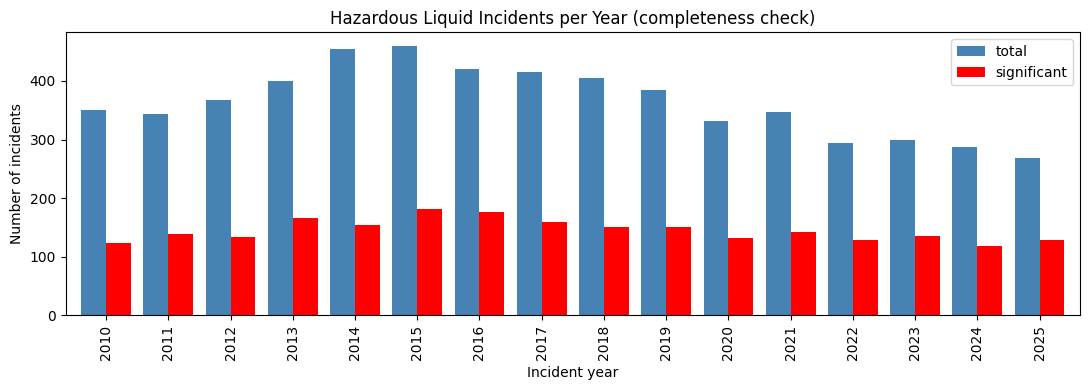

In [248]:
# incidents per year, total vs significant
by_year = incidents[incidents["IYEAR"] <= 2025].groupby("IYEAR").agg(total=("REPORT_NUMBER", "size"),
                                         significant=("SIGNIFICANT_FLAG", "sum"))

ax = by_year.plot(kind="bar", figsize=(11, 4), width=0.8, color=["steelblue", "Red"])
ax.set_title("Hazardous Liquid Incidents per Year (completeness check)")
ax.set_xlabel("Incident year")
ax.set_ylabel("Number of incidents")
plt.tight_layout()
plt.show()

**Observation**: 
Incidents per year peaked around 2014-2015 (about 455-460) and declined to about 270 by 2025. Significant incidents stayed roughly flat (about 120-180 per year). 2025 is in line with 2022-2024 with no sudden drop, so I treat it as complete enough to label the 2024 rows. The 2026 incidents in the PHMSA file are a partial year and were removed.

In [249]:
#  Count incidents and significant incidents for each operator and year
inc_year = incidents.groupby(["OPERATOR_ID", "IYEAR"]).agg(
    INCIDENTS=("REPORT_NUMBER", "nunique"),
    SIG_INCIDENTS=("SIGNIFICANT_FLAG", "sum"),
).reset_index()

print("Operator-years with at least one incident:", len(inc_year))
inc_year.head()

Operator-years with at least one incident: 1522


,OPERATOR_ID,IYEAR,INCIDENTS,SIG_INCIDENTS
0,00300,2010,11,3
1,00300,2011,12,7
2,00300,2012,26,4
3,00300,2013,20,6
4,00300,2014,34,7


In [250]:
#check if incidents match the annual panel

panel_keys = operator_year[KEYS].drop_duplicates()
m = incidents.merge(
    panel_keys, left_on=["OPERATOR_ID", "IYEAR"], right_on=KEYS, how="left", indicator=True)
print(m["_merge"].value_counts())
print(f"Incidents with an annual report that year: {(m['_merge'] == 'both').mean():.1%}")

_merge
both          5789
left_only       40
right_only       0
Name: count, dtype: int64
Incidents with an annual report that year: 99.3%


### Matching incidents to operators

5,789 of 5,829 incidents (99.3%) belong to an operator that filed an annual report that year. The other 40 (0.7%) have no annual report in their year, so they do not get their own row. They are still counted in the earlier-incident history and in the next-year label of the previous year. The operator IDs match well between the two files.

**Check: does the operator file a report the next year?** 
396 of 7,571 operator-years (5.2%) belong to an operator that files no annual report the following year, and their positive rate is lower (2.5% vs 12.8%). Some of this may be real, because operators that stop filing are often small or inactive. Some may be an artifact of mergers or ID changes, where next year's incidents are filed under a new ID. At most about 40 of the 926 positives (about 4%) could be affected. I keep these rows, because dropping them would use information about the future, and I do not use this column as a feature.

## 5. Incident history features and the target

For each operator and year we compute:
- **Same-year and prior-years incident counts** (known at the end of each yesr, so they are legitimate features).
- **Next-year significant incident count**, used only to build the label.

History starts in 2010, so "prior incidents" is undercounted for early years.

In [251]:
YEARS = list(range(2010, 2026))
print(YEARS)

[2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]


In [252]:
#turn the incident counts into a wide table, one row per operator, one column per year
def wide(col):
    """One row per operator, one column per year, 0 when there was no incident."""
    return (inc_year.pivot_table(index="OPERATOR_ID", columns="IYEAR", values=col,
                                 aggfunc="sum", fill_value=0)
                    .reindex(columns=YEARS, fill_value=0))

inc_w = wide("INCIDENTS")
sig_w = wide("SIG_INCIDENTS")

print("Grid shape (operators x years):", inc_w.shape)
inc_w.head(5)

Grid shape (operators x years): (354, 16)


IYEAR,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
OPERATOR_ID,,,,,,,,,,,,,,,,
00300,11,12,26,20,34,30,23,18,19,19,12,19,7,16,15,9
00395,3,0,0,0,0,0,0,0,1,0,0,0,1,1,0,1
00473,0,0,0,0,0,0,0,0,0,1,0,0,4,4,3,9
00515,0,0,0,0,1,0,0,0,0,0,0,2,1,1,0,0
00879,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0


In [253]:
# Incidents in EARLIER years: add up from the left, then slide one year to the right
inc_prior = inc_w.cumsum(axis=1).shift(1, axis=1).fillna(0)
sig_prior = sig_w.cumsum(axis=1).shift(1, axis=1).fillna(0)

# Significant incidents NEXT year: slide one year to the left
sig_next = sig_w.shift(-1, axis=1)

In [254]:
op = inc_year.sort_values("INCIDENTS", ascending=False)["OPERATOR_ID"].iloc[0]

check = pd.DataFrame({
    "this_year": inc_w.loc[op],
    "prior_years": inc_prior.loc[op],
    "sig_this_year": sig_w.loc[op],
    "sig_next_year": sig_next.loc[op],
})
print("Operator:", op)
check.T

Operator: 30829


IYEAR,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
this_year,13.0,28.0,24.0,31.0,28.0,48.0,28.0,39.0,32.0,22.0,16.0,29.0,22.0,11.0,17.0,24.0
prior_years,0.0,13.0,41.0,65.0,96.0,124.0,172.0,200.0,239.0,271.0,293.0,309.0,338.0,360.0,371.0,388.0
sig_this_year,2.0,10.0,10.0,6.0,7.0,12.0,7.0,13.0,7.0,9.0,6.0,7.0,5.0,3.0,4.0,10.0
sig_next_year,10.0,10.0,6.0,7.0,12.0,7.0,13.0,7.0,9.0,6.0,7.0,5.0,3.0,4.0,10.0,NaN


In [255]:
def to_long(table, name):
    out = table.copy()
    out.columns.name = "REPORT_YEAR"
    return out.stack().rename(name).reset_index()

history = (
    to_long(inc_w, "INCIDENTS_THIS_YEAR")
    .merge(to_long(sig_w, "SIG_INCIDENTS_THIS_YEAR"), on=KEYS)
    .merge(to_long(inc_prior, "INCIDENTS_PRIOR_YEARS"), on=KEYS)
    .merge(to_long(sig_prior, "SIG_INCIDENTS_PRIOR_YEARS"), on=KEYS)
    .merge(to_long(sig_next, "SIG_COUNT_NEXT_YEAR"), on=KEYS)   # used only to build the label
)
history["REPORT_YEAR"] = history["REPORT_YEAR"].astype(int)

print("History table:", history.shape)
history.head()

History table: (5664, 7)


,OPERATOR_ID,REPORT_YEAR,INCIDENTS_THIS_YEAR,SIG_INCIDENTS_THIS_YEAR,INCIDENTS_PRIOR_YEARS,SIG_INCIDENTS_PRIOR_YEARS,SIG_COUNT_NEXT_YEAR
0,00300,2010,11,3,0.0,0.0,7.0
1,00300,2011,12,7,11.0,3.0,4.0
2,00300,2012,26,4,23.0,10.0,6.0
3,00300,2013,20,6,49.0,14.0,7.0
4,00300,2014,34,7,69.0,20.0,7.0


In [256]:
rows_before = len(operator_year)
model_data = operator_year.merge(history, on=KEYS, how="left")
print("Rows before / after merge:", rows_before, "/", len(model_data))   # must be equal

# Operators with no incident on record get 0
hist_cols = ["INCIDENTS_THIS_YEAR", "SIG_INCIDENTS_THIS_YEAR",
             "INCIDENTS_PRIOR_YEARS", "SIG_INCIDENTS_PRIOR_YEARS"]
model_data[hist_cols] = model_data[hist_cols].fillna(0).astype(int)

Rows before / after merge: 8135 / 8135


Rows count matches , hence there is no duplicate merged rows.

In [257]:
# Park the 2025 rows, keep 2010-2024, build the target, drop the leaky column
scoring_2025 = model_data[model_data["REPORT_YEAR"] == 2025].copy()

model_data = model_data[model_data["REPORT_YEAR"] <= 2024].copy()

TARGET = "SIGNIFICANT_NEXT_YEAR"
model_data[TARGET] = (model_data["SIG_COUNT_NEXT_YEAR"].fillna(0) > 0).astype(int)
model_data = model_data.drop(columns="SIG_COUNT_NEXT_YEAR")   # must not stay as a feature

In [258]:
panel = set(zip(operator_year["OPERATOR_ID"], operator_year["REPORT_YEAR"]))
has_next = [(o, y + 1) in panel for o, y in zip(model_data["OPERATOR_ID"], model_data["REPORT_YEAR"])]
print(model_data.assign(HAS_NEXT_REPORT=has_next)
      .groupby("HAS_NEXT_REPORT")[TARGET].agg(positive_rate="mean", rows="size").round(3))

                 positive_rate  rows
HAS_NEXT_REPORT                     
False                    0.025   396
True                     0.128  7175


In [259]:
# Final checks
print("Modeling table:", model_data.shape)
print("Duplicate operator-years:", model_data.duplicated(KEYS).sum())   # must be 0
print(model_data[TARGET].value_counts())
print(f"Positive rate: {model_data[TARGET].mean():.1%}")

Modeling table: (7571, 87)
Duplicate operator-years: 0
SIGNIFICANT_NEXT_YEAR
0    6645
1     926
Name: count, dtype: int64
Positive rate: 12.2%


In [260]:
# Leakage check: only the target should mention "NEXT"
print([c for c in model_data.columns if "NEXT" in c or "TARGET" in c])
print("Rows parked for 2025 scoring:", len(scoring_2025))

['SIGNIFICANT_NEXT_YEAR']
Rows parked for 2025 scoring: 564


**Leakage Checks passed:**

 The modeling table has 7,571 operator-years (2010-2024) with no duplicates. The target is `SIGNIFICANT_NEXT_YEAR` (12.2% positive), and no other column contains next-year information. The 564 rows from 2025 are held out for scoring, since their labels would come from partial 2026 data.

In [261]:
# How concentrated are the positives? (a few big operators may account for many 1s)
top = (model_data.groupby("OPERATOR_NAME")[TARGET]
       .agg(positives="sum", years="size")
       .sort_values("positives", ascending=False)
       .head(10))
top["share_of_all_positives"] = (top["positives"] / model_data[TARGET].sum()).round(3)
print(top)
print("Top 10 share of all positives:", f"{top['share_of_all_positives'].sum():.1%}")

                                      positives  years  share_of_all_positives
OPERATOR_NAME                                                                 
COLONIAL PIPELINE CO                         15     15                   0.016
MARATHON PIPE LINE LLC                       15     15                   0.016
PLAINS PIPELINE, L.P.                        15     15                   0.016
KINDER MORGAN LIQUID TERMINALS, LLC          15     15                   0.016
BUCKEYE PARTNERS, LP                         15     15                   0.016
ENTERPRISE CRUDE PIPELINE LLC                15     15                   0.016
ENTERPRISE PRODUCTS OPERATING LLC            15     15                   0.016
SUNOCO PIPELINE L.P.                         15     15                   0.016
ENBRIDGE ENERGY, LIMITED PARTNERSHIP         14     15                   0.015
MAGELLAN PIPELINE COMPANY, LP                14     14                   0.015
Top 10 share of all positives: 15.8%


**Observation:** The 10 operators with the most positive rows are positive in 14-15 of their 15 years, and together make up 15.8% of all positive rows. Large operators therefore almost always have a significant incident the following year. A model could score well by learning operator size alone, so the baseline will be compared against size-only and history-only benchmarks, and results will be reported with and without the largest operators.

## 6. Data cleaning and outlier analysis

Columns with any missing values: 12 of 87


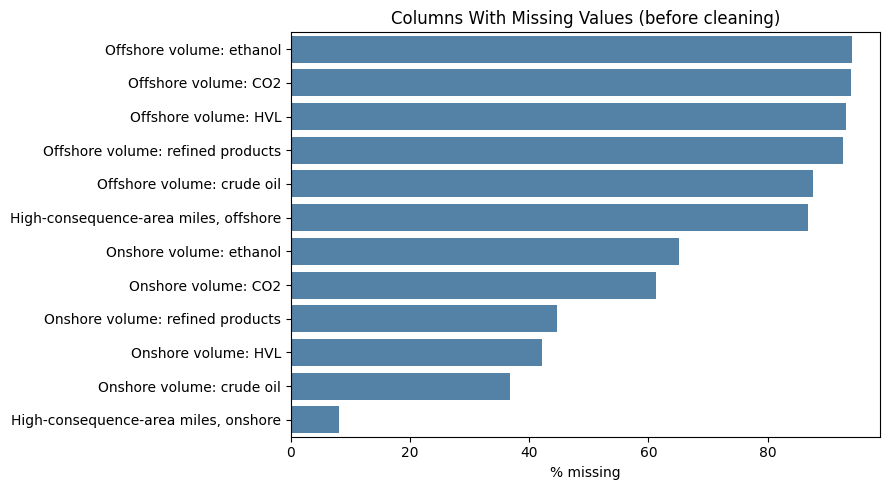

In [262]:
# Missing values before cleaning
missing_pct = (model_data.isna().mean() * 100).sort_values(ascending=False)
has_missing = missing_pct[missing_pct > 0]
print("Columns with any missing values:", len(has_missing), "of", model_data.shape[1])

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=has_missing.values, y=[READABLE.get(c, c) for c in has_missing.index], color="steelblue", ax=ax)
ax.set_title("Columns With Missing Values (before cleaning)")
ax.set_xlabel("% missing")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

**Observation:** Only 12 of the 87 columns have missing values, and all of them are Part B or Part C columns. The Part D and Part E columns have no blanks at all. The offshore columns are missing the most (87% to 94%), which makes sense because most operators have no offshore pipe. I think these blanks mean "does not apply" and not "forgot to report", but I want to check that before I fill them with 0.

In [263]:
# Are the Part C blanks just operators that don't carry that commodity?
pairs = {"PARTCONCRUDE": "Crude", "PARTCONHVL": "HVL", "PARTCONCO2": "CO2",
         "PARTCONRPP": "Refined", "PARTCONETHANOL": "Fuel"}

rows = []
for part_c, word in pairs.items():
    flag = [c for c in model_data.columns if c.startswith("COMMODITY_" + word)][0]
    carries = model_data[flag] == 1
    rows.append({
        "column": part_c,
        "blank_if_carries_%": round(model_data.loc[carries, part_c].isna().mean() * 100, 1),
        "blank_if_not_%": round(model_data.loc[~carries, part_c].isna().mean() * 100, 1),
    })
pd.DataFrame(rows)

,column,blank_if_carries_%,blank_if_not_%
0,PARTCONCRUDE,9.3,65.3
1,PARTCONHVL,1.0,63.6
2,PARTCONCO2,0.0,65.4
3,PARTCONRPP,3.3,67.3
4,PARTCONETHANOL,0.0,65.4


In [264]:
# If blank = 0, onshore + offshore should add up to the HCA total
parts = model_data[["PARTBHCAONSHORE", "PARTBHCAOFFSHORE"]].fillna(0).sum(axis=1)
mismatch = (parts - model_data["PARTBHCATOTAL"]).abs() > 0.5
print("Rows where onshore + offshore does not match the total:", int(mismatch.sum()))

Rows where onshore + offshore does not match the total: 0


In [265]:
# Fill the 12 columns that had blanks with 0 (blank = not applicable)
cols_to_fill = has_missing.index.tolist()
model_data[cols_to_fill] = model_data[cols_to_fill].fillna(0)

print("Missing values left in the table:", int(model_data.isna().sum().sum()))
print("Rows:", len(model_data))   # should still be 7571

Missing values left in the table: 0
Rows: 7571


In [266]:
# Part B to E columns (note: Part C is barrel-miles, not miles)
part_cols = [c for c in model_data.columns if c.startswith(("PARTB", "PARTC", "PARTD", "PARTE"))]
print("Number of Part B-E columns:", len(part_cols))

# 1. Negative values
neg_by_col = (model_data[part_cols] < 0).sum()
print("Negative values in total:", int(neg_by_col.sum()))

# 2. Columns with only one value
unique_counts = model_data[part_cols].nunique()
constant_cols = unique_counts[unique_counts <= 1].index.tolist()
print("Columns with only one value:", len(constant_cols))
print(constant_cols)

Number of Part B-E columns: 70
Negative values in total: 0
Columns with only one value: 3
['PARTCOFFCO2', 'PARTCOFFETHANOL', 'PARTDOFFCUP']


In [267]:
# Make sure the one value really is 0 (not some other constant number)
print(model_data[constant_cols].abs().sum())

# Drop them
model_data = model_data.drop(columns=constant_cols)
print("Shape after dropping:", model_data.shape)   # should be (7571, 84)

PARTCOFFCO2        0.0
PARTCOFFETHANOL    0.0
PARTDOFFCUP        0.0
dtype: float64
Shape after dropping: (7571, 84)


**Checks on the Part B-E columns:** There are 70 columns. None have negative values. Three columns have only one value (0 in every row): offshore CO2 and offshore ethanol volume in Part C, and one offshore column in Part D. Nobody moves those products offshore, so they carry no information and I dropped them. The table now has 7,571 rows and 84 columns.

In [268]:
# Total pipe miles = Part D onshore total + offshore total
model_data["TOTAL_MILES"] = model_data[["PARTDONTOTAL", "PARTDOFFTOTAL"]].sum(axis=1)

no_size = model_data["TOTAL_MILES"] <= 0
print("Rows with no Part D miles:", int(no_size.sum()), f"({no_size.mean():.1%})")

print(model_data.groupby(no_size.rename("NO_SIZE"))[TARGET]
      .agg(positive_rate="mean", rows="size").round(3))

model_data["TOTAL_MILES"].describe().round(1)

Rows with no Part D miles: 268 (3.5%)
         positive_rate  rows
NO_SIZE                     
False            0.125  7303
True             0.045   268


count     7571.0
mean       419.0
std       1573.1
min          0.0
25%          7.7
50%         34.9
75%        171.3
max      24138.5
Name: TOTAL_MILES, dtype: float64

In [269]:
# Mark operator-years with no Part D miles (size unknown)
model_data["NO_SIZE_REPORTED"] = (model_data["TOTAL_MILES"] <= 0).astype(int)
print(model_data["NO_SIZE_REPORTED"].value_counts())

NO_SIZE_REPORTED
0    7303
1     268
Name: count, dtype: int64


In [270]:
# 1. Who has the most miles? (are the biggest numbers the biggest companies?)
print(model_data.groupby("OPERATOR_NAME")["TOTAL_MILES"].max()
      .sort_values(ascending=False).head(6).round(0).to_string())

# 2. Who has no size reported?
print("\nMost frequent operators with no Part D miles:")
print(model_data.loc[model_data["NO_SIZE_REPORTED"] == 1, "OPERATOR_NAME"]
      .value_counts().head(6).to_string())

# 3. ERW pipe is only part of the total, so it should not be bigger than the total
too_big = model_data["PARTETOTAL"] > model_data["TOTAL_MILES"] * 1.01
print("\nRows where ERW miles are bigger than total miles:", int(too_big.sum()))

OPERATOR_NAME
ENTERPRISE PRODUCTS OPERATING LLC    24139.0
ONEOK NGL PIPELINE, LLC              13982.0
PHILLIPS 66 PIPELINE LLC             12305.0
MAGELLAN PIPELINE COMPANY, LP        11962.0
CONOCOPHILLIPS                       11169.0
PLAINS PIPELINE, L.P.                 9942.0

Most frequent operators with no Part D miles:
OPERATOR_NAME
CHEVRON PRODUCTS COMPANY                15
OP RENO LLC                             15
ENBRIDGE STORAGE (PATOKA) L.L.C.        14
FLINT HILLS RESOURCES PINE BEND, LLC    13
RANCHO LPG HOLDINGS, LLC                13
EXXONMOBIL BILLINGS REFINERY            12

Rows where ERW miles are bigger than total miles: 20


In [271]:
too_big = model_data["PARTETOTAL"] > model_data["TOTAL_MILES"] * 1.01

cols = ["OPERATOR_NAME", "REPORT_YEAR", "TOTAL_MILES", "PARTETOTAL", "NO_SIZE_REPORTED"]
print(model_data.loc[too_big, cols].sort_values("PARTETOTAL", ascending=False).head(10).to_string(index=False))

print("\nOf the", int(too_big.sum()), "rows, how many have no size reported:",
      int(model_data.loc[too_big, "NO_SIZE_REPORTED"].sum()))

                          OPERATOR_NAME  REPORT_YEAR  TOTAL_MILES  PARTETOTAL  NO_SIZE_REPORTED
       EXXONMOBIL OIL CORP - WEST COAST         2015      638.850     764.110                 0
                TRINITY PIPELINE GP LLC         2010      158.000     196.000                 0
                      CENTRAL CRUDE INC         2024        0.000      79.700                 1
                               MIPC LLC         2019       51.671      79.491                 0
                               MIPC LLC         2020       51.671      79.491                 0
     CITGO REFINING & CHEMICAL CO. L.P.         2010       58.200      62.600                 0
IRONWOOD MIDSTREAM ENERGY PARTNERS, LLC         2022       49.159      59.988                 0
                      LM TOUCHDOWN, LLC         2020       17.050      42.540                 0
                      REO OPERATING LLC         2018        0.000      34.150                 1
          TAPROOT ROCKIES MIDSTREAM LLC 

In [272]:
# ERW pipe is part of the total pipe, so total miles can't be smaller than ERW miles
before_zero = int((model_data["TOTAL_MILES"] <= 0).sum())

model_data["TOTAL_MILES"] = model_data[["TOTAL_MILES", "PARTETOTAL"]].max(axis=1)

# Recompute the flag with the new size
model_data["NO_SIZE_REPORTED"] = (model_data["TOTAL_MILES"] <= 0).astype(int)
after_zero = int(model_data["NO_SIZE_REPORTED"].sum())

print("Rows with no size, before / after:", before_zero, "/", after_zero)
print("Rows where ERW is still bigger than total:",
      int((model_data["PARTETOTAL"] > model_data["TOTAL_MILES"] * 1.01).sum()))

Rows with no size, before / after: 268 / 261
Rows where ERW is still bigger than total: 0


In [273]:
print(model_data.groupby("NO_SIZE_REPORTED")[TARGET]
      .agg(positive_rate="mean", rows="size").round(3))


                  positive_rate  rows
NO_SIZE_REPORTED                     
0                         0.125  7310
1                         0.042   261


261 operator-years (3.4%) still have no pipe miles after I set `TOTAL_MILES` to the larger of the Part D total and the ERW miles. Their positive rate is much lower (4.2% vs 12.5%), but that is only about 11 positive rows, so I don't read much into the exact number. Many of them look like storage or refinery operators (for example Chevron Products and ExxonMobil Billings Refinery). I keep them with `TOTAL_MILES = 0` and the `NO_SIZE_REPORTED` flag instead of dropping them or guessing a size.

In [274]:
# Mileage is very skewed, so I look for outliers on the log scale
model_data["LOG_TOTAL_MILES"] = np.log1p(model_data["TOTAL_MILES"])

# Only rows with a reported size (zeros would distort the quartiles)
sized = model_data[model_data["NO_SIZE_REPORTED"] == 0]

q1, q3 = sized["LOG_TOTAL_MILES"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr

print(f"Fences on the log scale: {low:.2f} to {high:.2f}")
print(f"Fences in miles: {max(np.expm1(low), 0):.1f} to {np.expm1(high):,.0f}")

is_low = sized["LOG_TOTAL_MILES"] < low
is_high = sized["LOG_TOTAL_MILES"] > high
print("Too small:", int(is_low.sum()), "| too large:", int(is_high.sum()),
      f"({(is_low | is_high).mean():.1%} of rows with a size)")

# Do the outliers behave differently?
group = pd.Series("typical", index=sized.index)
group[is_high] = "very large"
group[is_low] = "very small"
print(sized.groupby(group)[TARGET].agg(positive_rate="mean", rows="size").round(3))

Fences on the log scale: -1.93 to 9.48
Fences in miles: 0.0 to 13,055
Too small: 0 | too large: 20 (0.3% of rows with a size)
            positive_rate  rows
typical             0.123  7290
very large          1.000    20


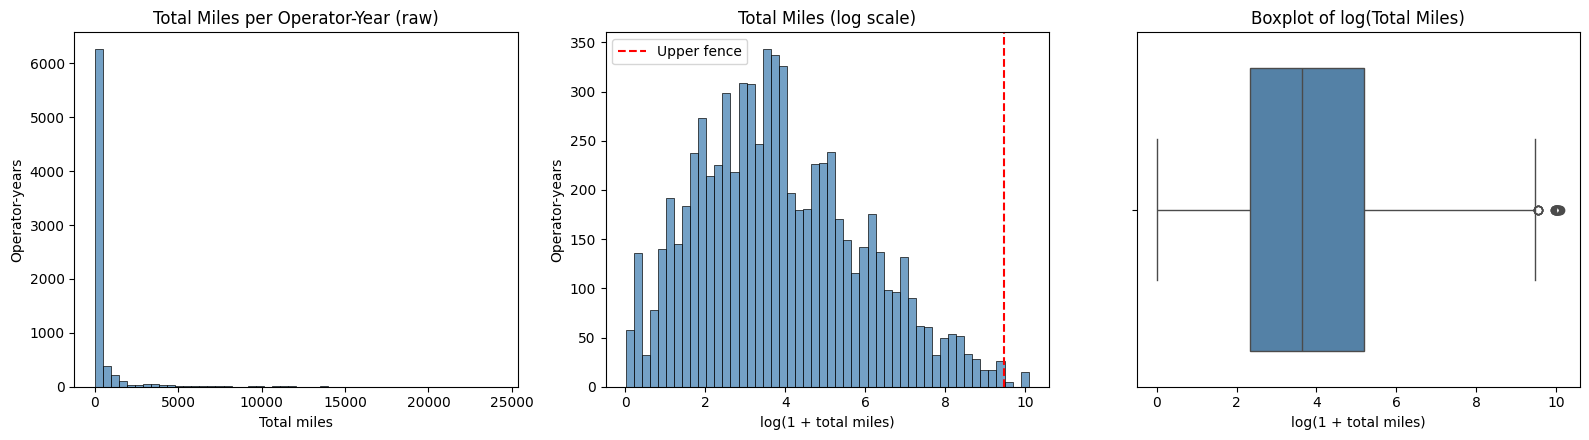

In [275]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.histplot(sized["TOTAL_MILES"], bins=50, color="steelblue", ax=axes[0])
axes[0].set_title("Total Miles per Operator-Year (raw)")
axes[0].set_xlabel("Total miles")
axes[0].set_ylabel("Operator-years")

sns.histplot(sized["LOG_TOTAL_MILES"], bins=50, color="steelblue", ax=axes[1])
axes[1].axvline(high, color="red", linestyle="--", label="Upper fence")
axes[1].set_title("Total Miles (log scale)")
axes[1].set_xlabel("log(1 + total miles)")
axes[1].set_ylabel("Operator-years")
axes[1].legend()

sns.boxplot(x=sized["LOG_TOTAL_MILES"], color="steelblue", ax=axes[2])
axes[2].set_title("Boxplot of log(Total Miles)")
axes[2].set_xlabel("log(1 + total miles)")

plt.tight_layout()
plt.show()

**What the plots show:** On the raw scale, most operator-years are small (about 85% are under 500 miles) and a few are huge, so the histogram is hard to read. On the log scale the shape is much more even, with a typical operator at about 35 miles. The boxplot shows no small outliers, and the 20 very large operator-years sit past the upper fence of about 13,000 miles.

In [276]:
big = sized[is_high]
print(big.groupby("OPERATOR_NAME")
         .agg(years=("REPORT_YEAR", "size"),
              min_miles=("TOTAL_MILES", "min"),
              max_miles=("TOTAL_MILES", "max"))
         .round(0)
         .sort_values("years", ascending=False)
         .to_string())

                                   years  min_miles  max_miles
OPERATOR_NAME                                                 
ENTERPRISE PRODUCTS OPERATING LLC     15    21358.0    24139.0
ONEOK NGL PIPELINE, LLC                5    13830.0    13982.0


**Outlier analysis on `TOTAL_MILES`:** Mileage is very right-skewed (median about 35 miles, max about 24,000), so I checked for outliers on the log scale using the IQR rule, leaving out the 261 operator-years with no size. The upper fence is about 13,055 miles, and 20 rows (0.3%) are above it. They come from only two operators: Enterprise Products Operating LLC (15 years, 21,358 to 24,139 miles) and ONEOK NGL Pipeline LLC (5 years, about 13,800 to 14,000 miles). No rows are below the lower fence, because `log(1 + miles)` cannot go below 0.

All 20 rows have a significant incident the next year (100%, versus 12.3% for typical rows), but since they come from just two companies this is not much evidence. These are real, very large pipeline companies and not data errors, so I **keep them** and use the log of mileage as a feature. Dropping them would remove the operators with the most risk. I will check the models with and without these two operators.

### Data Cleaning summary

| Step | Result |
|---|---|
| Duplicates | 0 |
| Missing values | 12 columns filled with 0 (checked first) |
| Negative values | 0 |
| Constant columns | 3 dropped |
| Size measure | TOTAL_MILES built from Part D, checked against ERW |
| Rows with no size reported | 261 kept, with a flag |
| Outliers | 20 rows from 2 operators, kept |

In [277]:
model_data.to_csv(PROCESSED_DIR / "checkpoint_after_cleaning.csv", index=False)
print("Saved:", model_data.shape)

Saved: (7571, 87)


## 7. Feature engineering

Raw mileage and volume numbers are hard to compare between a tiny operator and a huge one, so I'm turning them into shares(%) and logs. Everything below uses only year *t* or earlier.

My plan:
1. **Size and pipe type:** how much of the pipe is ERW(electric resistance welded pipe), and how much could affect high consequence areas (HCA)
2. **Volume moved (Part C):** total barrel-miles (log) and the share that is offshore
3. **Incident history:** simple yes/no flags and a log of earlier incidents
4. **Pipe age and materials (Parts D and E):** I'll do this last, once I've looked at the column names

In [278]:
# Share of the operator's pipe that is ERW (0 when we have no size)
model_data["HAS_ERW_PIPE"] = (model_data["PARTETOTAL"] > 0).astype(int)
model_data["ERW_SHARE"] = model_data["PARTETOTAL"].div(model_data["TOTAL_MILES"].replace(0, np.nan)).fillna(0)

# Share of the pipe that could affect HCAs
hca_raw = model_data["PARTBHCATOTAL"].div(model_data["TOTAL_MILES"].replace(0, np.nan)).fillna(0)
print("Rows where HCA miles are more than 100% of total miles:", int((hca_raw > 1).sum()))

# A share can't be more than 100%, so I cap it at 1
model_data["HCA_SHARE"] = hca_raw.clip(upper=1)

model_data[["ERW_SHARE", "HCA_SHARE"]].describe().round(2)

Rows where HCA miles are more than 100% of total miles: 42


,ERW_SHARE,HCA_SHARE
count,7571.00,7571.00
mean,0.69,0.47
std,0.41,0.40
min,0.00,0.00
25%,0.27,0.04
50%,1.00,0.42
75%,1.00,1.00
max,1.00,1.00


In [279]:
# Share of 100%: how many rows, and does Part E just equal Part D?
d_total = model_data["PARTDONTOTAL"] + model_data["PARTDOFFTOTAL"]
share_one = model_data["ERW_SHARE"] >= 0.999
print("Rows with ERW_SHARE of 100%:", int(share_one.sum()), f"({share_one.mean():.1%})")

same = share_one & np.isclose(model_data["PARTETOTAL"], d_total)
print("  of those, ERW miles equal the Part D miles:", int(same.sum()))

# Are the big operators in that group?
print(model_data.loc[share_one].groupby("OPERATOR_NAME")["TOTAL_MILES"].max()
      .sort_values(ascending=False).head(5).round(0).to_string())

# Positive rate by ERW share group
bucket = pd.cut(model_data["ERW_SHARE"], [-0.01, 0, 0.5, 0.99, 1.0],
                labels=["none", "under 50%", "50-99%", "100%"])
print(model_data.groupby(bucket, observed=True)[TARGET]
      .agg(positive_rate="mean", rows="size").round(3))

Rows with ERW_SHARE of 100%: 3760 (49.7%)
  of those, ERW miles equal the Part D miles: 3558
OPERATOR_NAME
ONEOK NGL PIPELINE LP                         7996.0
NUSTAR PIPELINE OPERATING PARTNERSHIP L.P.    4377.0
EXXONMOBIL PIPELINE CO                        4124.0
NUSTAR LOGISTICS, L.P.                        3745.0
DCP MIDSTREAM                                 3586.0
           positive_rate  rows
ERW_SHARE                     
none               0.046  1469
under 50%          0.239   815
50-99%             0.286  1357
100%               0.070  3930


### Volume features (Part C)

Part C is the volume each operator moves, split into onshore and offshore columns. A few operators move huge amounts, so I take the log of the total. I also add the share of the volume that is offshore.

In [280]:
# I think Part C is barrel-miles, so I just call it volume
part_c = [c for c in model_data.columns if c.startswith("PARTC")]
offshore_c = [c for c in part_c if c.startswith("PARTCOFF")]
print("Part C columns:", len(part_c), "| offshore:", len(offshore_c))

volume = model_data[part_c].sum(axis=1)
model_data["LOG_VOLUME"] = np.log1p(volume)

# share of the volume that is offshore (0 when there is no volume)
model_data["OFFSHORE_VOLUME_SHARE"] = (model_data[offshore_c].sum(axis=1)
                                       .div(volume.replace(0, np.nan)).fillna(0))

print("Rows with no volume reported:", int((volume <= 0).sum()))
model_data[["LOG_VOLUME", "OFFSHORE_VOLUME_SHARE"]].describe().round(2)

Part C columns: 8 | offshore: 3
Rows with no volume reported: 859


,LOG_VOLUME,OFFSHORE_VOLUME_SHARE
count,7571.00,7571.00
mean,16.18,0.05
std,7.10,0.21
min,0.00,0.00
25%,13.88,0.00
50%,17.90,0.00
75%,21.08,0.00
max,27.85,1.00


In [281]:
model_data["NO_VOLUME_REPORTED"] = (volume <= 0).astype(int)

print(pd.crosstab(model_data["NO_SIZE_REPORTED"], model_data["NO_VOLUME_REPORTED"]))
print(model_data.groupby("NO_VOLUME_REPORTED")[TARGET]
      .agg(positive_rate="mean", rows="size").round(3))

NO_VOLUME_REPORTED     0    1
NO_SIZE_REPORTED             
0                   6704  606
1                      8  253
                    positive_rate  rows
NO_VOLUME_REPORTED                     
0                           0.135  6712
1                           0.027   859


**Observation:** Part C has 8 columns (3 offshore). 859 operator-years (11.3%) report no volume at all, which is more than the 261 with no size. Most operator-years with no size (253 of 261) also have no volume, but 606 operator-years have pipe miles and no volume. Operators with no volume have a much lower positive rate (2.7% vs 13.5%), though that is only about 23 positive rows. `LOG_VOLUME` has a spike at 0 for these rows, so I add a flag, `NO_VOLUME_REPORTED`, and keep them. Fewer than a quarter of operator-years have any offshore volume, so `OFFSHORE_VOLUME_SHARE` is 0 for most rows.

### Incident history flags

Did the operator have a significant incident this year, or in earlier years? These only use year *t* or earlier, so nothing from the future leaks in. I also take the log of the earlier incident count, because a few operators have hundreds.

In [282]:
model_data["HAD_SIG_THIS_YEAR"] = (model_data["SIG_INCIDENTS_THIS_YEAR"] > 0).astype(int)
model_data["HAD_SIG_PRIOR"] = (model_data["SIG_INCIDENTS_PRIOR_YEARS"] > 0).astype(int)
model_data["LOG_INCIDENTS_PRIOR"] = np.log1p(model_data["INCIDENTS_PRIOR_YEARS"])

print(model_data.groupby("HAD_SIG_THIS_YEAR")[TARGET].agg(positive_rate="mean", rows="size").round(3))
print(model_data.groupby("HAD_SIG_PRIOR")[TARGET].agg(positive_rate="mean", rows="size").round(3))

                   positive_rate  rows
HAD_SIG_THIS_YEAR                     
0                          0.068  6657
1                          0.519   914
               positive_rate  rows
HAD_SIG_PRIOR                     
0                      0.050  5619
1                      0.329  1952


**Observation:** 
Operators with a significant incident this year are much more likely to have one next year (51.9%, 914 rows) than those without (6.8%, 6,657 rows). The same holds for earlier years (32.9% vs 5.0%). A simple rule that predicts 1 whenever the operator had a significant incident this year would have about 52% precision and catch about half of the 926 positives, so this is the baseline a model has to beat. The harder cases are the roughly 450 positives among the operators with no significant incident this year. Incident history only starts in 2010, so early years have less history to draw on.

### Part E share as groups

The share of pipe in Part E did not go up or down in a straight line with the target (4.6% for none, 24-29% for partial, 7% for all). A plain logistic regression assumes a straight line, so I turn it into three groups: none, partial, all. I call it "Part E share" and not "ERW share" because for about half of operators it equals the Part D total, so I'm not sure it covers only ERW pipe.

In [283]:
model_data["ERW_GROUP"] = np.select(
    [model_data["ERW_SHARE"] == 0, model_data["ERW_SHARE"] >= 0.999],
    ["none", "all"], default="partial")

print(model_data["ERW_GROUP"].value_counts())
print(model_data.groupby("ERW_GROUP")[TARGET].agg(positive_rate="mean", rows="size").round(3))
print(model_data.shape)   # expect (7571, 96)

ERW_GROUP
all        3760
partial    2342
none       1469
Name: count, dtype: int64
           positive_rate  rows
ERW_GROUP                     
all                0.065  3760
none               0.046  1469
partial            0.263  2342
(7571, 97)


**Observation:**

 Operators with all of their pipe in Part E (3,760 rows) have a positive rate of 6.5%, and operators with none (1,469 rows) have 4.6%. Operators with a mix (2,342 rows) have 26.3%, much higher than both. The relationship is not a straight line, so I use three groups. Because Part E equals the Part D total for about half of operators, I call this "Part E share" and not "ERW share", and I did not check whether the "partial" group is simply made up of larger operators.

In [284]:
# Pipe age: Part E miles are split by the decade the pipe was installed.
# Miles installed before 1970 are treated as older pipe.
old_pipe_cols = ["PARTEPRE40TOTAL", "PARTE1940TOTAL", "PARTE1950TOTAL", "PARTE1960TOTAL"]
decade_cols = old_pipe_cols + ["PARTE1970TOTAL", "PARTE1980TOTAL", "PARTE1990TOTAL",
                               "PARTE2000TOTAL", "PARTE2010TOTAL", "PARTE2020TOTAL", "PARTEUNKNTOTAL"]

# Check that the decade columns add up to the Part E total before using them
decades_match = np.isclose(model_data[decade_cols].sum(axis=1), model_data["PARTETOTAL"])
print("Rows where the decade columns add up to the Part E total:", int(decades_match.sum()), "of", len(model_data))

# Share of Part E miles installed before 1970 (0 when there is no Part E pipe)
model_data["OLD_PIPE_SHARE"] = (model_data[old_pipe_cols].sum(axis=1)
                                .div(model_data["PARTETOTAL"].replace(0, np.nan)).fillna(0))

old_groups = pd.cut(model_data["OLD_PIPE_SHARE"], [-0.01, 0, 0.5, 1.0],
                    labels=["None before 1970", "Under half", "Half or more"])
print(model_data.groupby(old_groups, observed=True)[TARGET].agg(positive_rate="mean", rows="size").round(3))

Rows where the decade columns add up to the Part E total: 7571 of 7571
                  positive_rate  rows
OLD_PIPE_SHARE                       
None before 1970          0.051  4915
Under half                0.331  1291
Half or more              0.181  1365


In [285]:
# Recent significant incidents: this year and the two years before it
sig_by_op_year = incidents.groupby(["OPERATOR_ID", "IYEAR"])["SIGNIFICANT_FLAG"].sum()

def sig_last_3_years(op, year):
    return sum(sig_by_op_year.get((op, y), 0) for y in range(year - 2, year + 1))

model_data["SIG_LAST3"] = [sig_last_3_years(o, y)
                           for o, y in zip(model_data["OPERATOR_ID"], model_data["REPORT_YEAR"])]

# Past incidents per mile: incident history scaled by pipe size
model_data["LOG_PRIOR_INC_PER_MILE"] = np.log1p(
    model_data["INCIDENTS_PRIOR_YEARS"] / np.maximum(model_data["TOTAL_MILES"], 1))

print(model_data[["SIG_LAST3", "LOG_PRIOR_INC_PER_MILE"]].describe().round(2))

       SIG_LAST3  LOG_PRIOR_INC_PER_MILE
count    7571.00                 7571.00
mean        0.81                    0.03
std         3.09                    0.18
min         0.00                    0.00
25%         0.00                    0.00
50%         0.00                    0.00
75%         0.00                    0.01
max        45.00                    3.89


In [286]:
model_data.to_csv(PROCESSED_DIR / "checkpoint_after_features.csv", index=False)
print("Saved:", model_data.shape)

Saved: (7571, 100)


## 8. Exploratory data analysis

I look at how often an operator has a significant incident next year (the positive rate) across different groups. I use percentages, so 12% means 12 out of every 100 operator-years.

Plot 1: rate by year

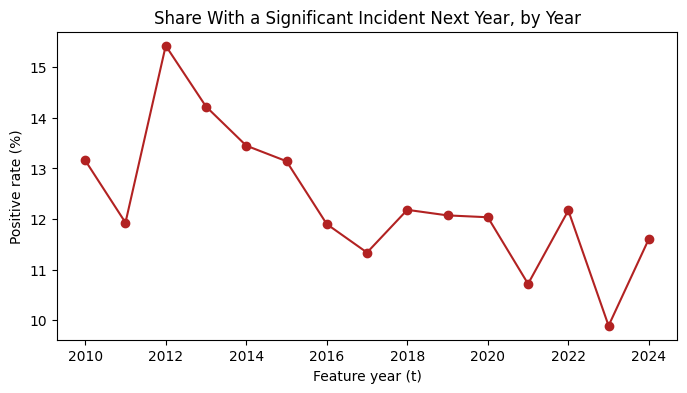

In [287]:
# positive rate for each year (in percent)
rate_by_year = model_data.groupby("REPORT_YEAR")[TARGET].mean() * 100

plt.figure(figsize=(8, 4))
plt.plot(rate_by_year.index, rate_by_year.values, marker="o", color="firebrick")
plt.title("Share With a Significant Incident Next Year, by Year")
plt.xlabel("Feature year (t)")
plt.ylabel("Positive rate (%)")
plt.show()

**Observation:** The share of operator-years with a significant incident the next year stays between about 10% and 15% in every year. It peaks at about 15.4% (2012) and drifts down to about 10-12% in recent years, with a low of about 9.9% in 2023. This fits the decline in incidents per year. The target is fairly stable over time, but a test set from the latest years will have a slightly lower base rate than the training years.

Plot 2: rate by operator size

            mean  size
SIZE_GROUP            
Q1 small     1.3  1828
Q2           2.7  1829
Q3           8.2  1835
Q4 large    38.0  1818


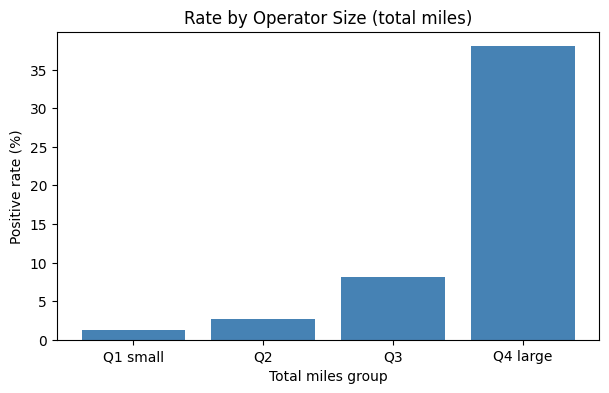

In [288]:
# only the operators that have a size
size_data = model_data[model_data["NO_SIZE_REPORTED"] == 0].copy()

# split them into 4 equal groups by total miles
size_data["SIZE_GROUP"] = pd.qcut(size_data["TOTAL_MILES"], 4,
                                  labels=["Q1 small", "Q2", "Q3", "Q4 large"])

# positive rate and number of rows in each group
size_rates = size_data.groupby("SIZE_GROUP", observed=True)[TARGET].agg(["mean", "size"])
size_rates["mean"] = size_rates["mean"] * 100
print(size_rates.round(1))

plt.figure(figsize=(7, 4))
plt.bar(size_rates.index.astype(str), size_rates["mean"], color="steelblue")
plt.title("Rate by Operator Size (total miles)")
plt.xlabel("Total miles group")
plt.ylabel("Positive rate (%)")
plt.show()

**Observation :** Operator size separates the target more than anything else so far. The positive rate is about 1.3% for the smallest quarter of operators, 2.7% for Q2, 8% for Q3, and about 38% for the largest quarter. The largest quarter holds roughly three-quarters of all positive rows. Size alone would already give a decent prediction, so the model has to be judged against a size-only baseline.

Plot 3: rate by earlier significant incidents

                           mean  size
SIG_INCIDENTS_PRIOR_YEARS            
0                           5.0  5619
1                          13.1   787
2-3                        24.6   455
4+                         60.3   710


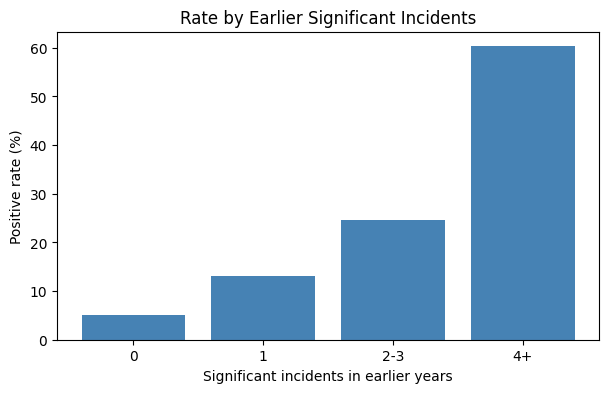

In [289]:
# group operators by how many significant incidents they had in earlier years
prior_group = pd.cut(model_data["SIG_INCIDENTS_PRIOR_YEARS"], [-1, 0, 1, 3, np.inf],
                     labels=["0", "1", "2-3", "4+"])

prior_rates = model_data.groupby(prior_group, observed=True)[TARGET].agg(["mean", "size"])
prior_rates["mean"] = prior_rates["mean"] * 100
print(prior_rates.round(1))

plt.figure(figsize=(7, 4))
plt.bar(prior_rates.index.astype(str), prior_rates["mean"], color="steelblue")
plt.title("Rate by Earlier Significant Incidents")
plt.xlabel("Significant incidents in earlier years")
plt.ylabel("Positive rate (%)")
plt.show()

**Observation :** The positive rate goes up with every step of earlier significant incidents: about 5% for none, 13% for one, 24.5% for two or three, and about 60% for four or more. Operators with a long history of significant incidents almost always have another one. This overlaps with size, because big operators build up more incidents.

Plot 4: rate by Part E group

           mean  size
ERW_GROUP            
none        4.6  1469
partial    26.3  2342
all         6.5  3760


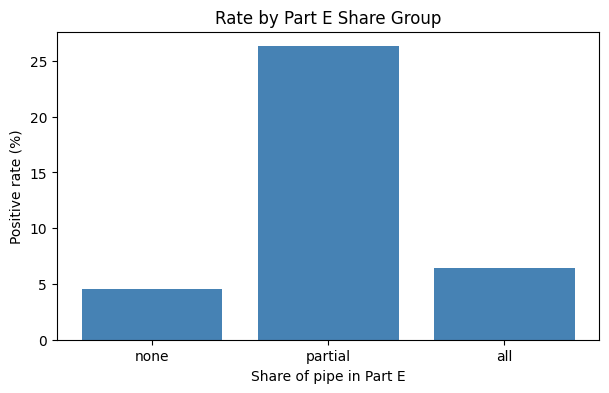

In [290]:
# put the groups in a sensible order
order = ["none", "partial", "all"]
erw_rates = model_data.groupby("ERW_GROUP")[TARGET].agg(["mean", "size"]).loc[order]
erw_rates["mean"] = erw_rates["mean"] * 100
print(erw_rates.round(1))

plt.figure(figsize=(7, 4))
plt.bar(erw_rates.index, erw_rates["mean"], color="steelblue")
plt.title("Rate by Part E Share Group")
plt.xlabel("Share of pipe in Part E")
plt.ylabel("Positive rate (%)")
plt.show()

**Observation :** Operators with a mix of Part E and other pipe have a much higher rate (about 26%) than those with none (about 4.5%) or all (about 6.5%). The relationship is not a straight line, so I use three groups. The "partial" group may be made up of larger operators, which I did not separate from size.

In [291]:
# Does earlier history still matter inside each size group?
print((size_data.pivot_table(index="SIZE_GROUP", columns="HAD_SIG_PRIOR",
                             values=TARGET, aggfunc="mean", observed=True) * 100).round(1))

print(size_data.pivot_table(index="SIZE_GROUP", columns="HAD_SIG_PRIOR",
                            values=TARGET, aggfunc="size", observed=True))

HAD_SIG_PRIOR     0     1
SIZE_GROUP               
Q1 small        1.0   5.6
Q2              2.3   6.0
Q3              6.4  13.8
Q4 large       20.6  48.3
HAD_SIG_PRIOR     0     1
SIZE_GROUP               
Q1 small       1704   124
Q2             1630   199
Q3             1385   450
Q4 large        674  1144


**Observation (earlier incidents within each size group):**

 In every size group, operators with earlier significant incidents have a higher positive rate than those without: 5.6% vs 1.0% (Q1), 6.0% vs 2.3% (Q2), 13.8% vs 6.4% (Q3) and 48.3% vs 20.6% (Q4). So incident history adds information beyond size, and size matters even for operators with no history (1.0% to 20.6%). Most positives are in the largest size group, where the model has to separate operators that are already high risk. The Q1 and Q2 cells with history are small (124 and 199 rows), so those rates are noisy.

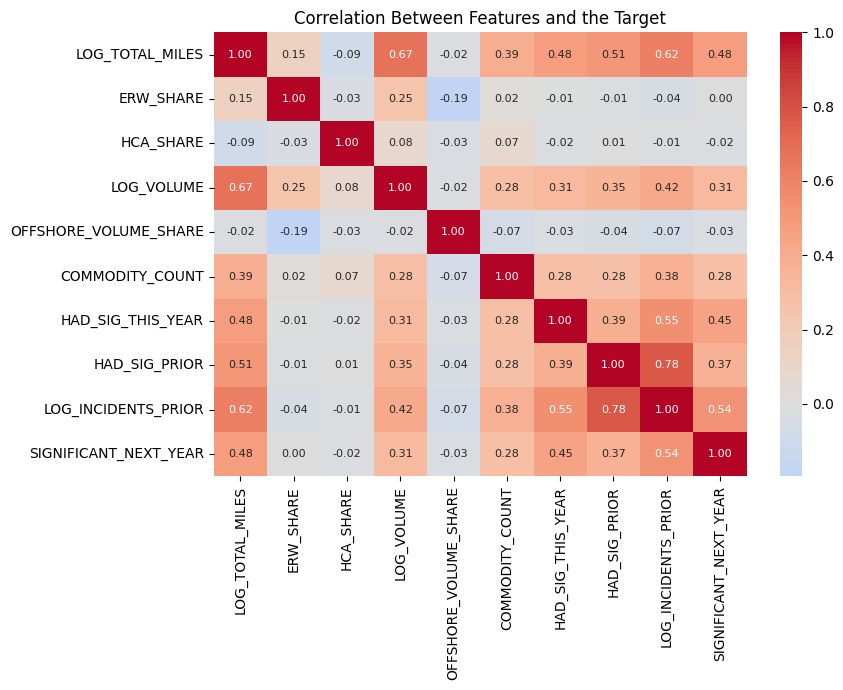

In [292]:
# the features I built, plus the target
corr_cols = ["LOG_TOTAL_MILES", "ERW_SHARE", "HCA_SHARE", "LOG_VOLUME", "OFFSHORE_VOLUME_SHARE",
             "COMMODITY_COUNT", "HAD_SIG_THIS_YEAR", "HAD_SIG_PRIOR", "LOG_INCIDENTS_PRIOR", TARGET]
corr = model_data[corr_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 8})
plt.title("Correlation Between Features and the Target")
plt.tight_layout()
plt.show()

**Observation :** 

The features most correlated with the target are the number of earlier incidents (0.54), operator size (0.48) and a significant incident this year (0.45). The earlier-incident flag and the earlier-incident count overlap strongly (0.78), and size overlaps with volume (0.67), so some of these features carry similar information. Nothing is above 0.8. `ERW_SHARE` has no correlation with the target (0.00), but that is because the relationship is not a straight line (4.5%, 26%, 6.5% across the three groups), which is why I use the groups instead. `HCA_SHARE` and `OFFSHORE_VOLUME_SHARE` are close to 0 and look weak.

In [293]:
# Chi-square tests: does the next-year rate differ across groups?
from scipy import stats

def fmt_p(p):
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"

# 1. Size groups vs next-year significant incident
size_ct = pd.crosstab(size_data["SIZE_GROUP"], size_data[TARGET])
chi2, p, dof, _ = stats.chi2_contingency(size_ct)
print(f"Size group vs next-year significant incident: chi-square = {chi2:.1f}, df = {dof}, {fmt_p(p)}")

# 2. Earlier significant incidents vs next-year significant incident (all operators)
prior_ct = pd.crosstab(model_data["HAD_SIG_PRIOR"], model_data[TARGET])
chi2, p, dof, _ = stats.chi2_contingency(prior_ct)
print(f"Earlier significant incident vs next-year significant incident: chi-square = {chi2:.1f}, df = {dof}, {fmt_p(p)}")

Size group vs next-year significant incident: chi-square = 1479.9, df = 3, p < 0.001
Earlier significant incident vs next-year significant incident: chi-square = 1048.2, df = 1, p < 0.001


### Are the differences real? (chi-square tests)

A chi-square test checks whether the next-year rate differs across groups more than chance would explain. A p-value below 0.05 means the difference is unlikely to be chance alone.

- **Size groups:** the next-year rate differs significantly across size groups (chi-square = 1479.9, df = 3, p < 0.001). Larger operators really do have higher rates.
- **Earlier significant incidents:** operators with an earlier significant incident have a significantly higher next-year rate (chi-square = 1048.2, df = 1, p < 0.001).

These tests show that the differences are not chance. They do not show that size or past incidents cause the risk. That is what the models are for.

In [294]:
model_data.to_csv(PROCESSED_DIR / "checkpoint_after_eda.csv", index=False)
print("Saved:", model_data.shape)

Saved: (7571, 100)


## 9. Baseline Model

In [295]:
train = model_data[model_data["REPORT_YEAR"] <= 2020]
test = model_data[model_data["REPORT_YEAR"] >= 2021]

print("Train years:", train["REPORT_YEAR"].min(), "to", train["REPORT_YEAR"].max(), "| rows:", len(train))
print("Test years: ", test["REPORT_YEAR"].min(), "to", test["REPORT_YEAR"].max(), "| rows:", len(test))
print(f"Positive rate - train: {train[TARGET].mean():.1%} | test: {test[TARGET].mean():.1%}")
print("Positives - train:", int(train[TARGET].sum()), "| test:", int(test[TARGET].sum()))

Train years: 2010 to 2020 | rows: 5309
Test years:  2021 to 2024 | rows: 2262
Positive rate - train: 12.7% | test: 11.1%
Positives - train: 675 | test: 251


**Train/test split:** 

I split by year instead of randomly, because the same operators appear in many years and a random split would put them in both sets. Training uses 2010-2020 (5,309 rows, 675 positives, 12.7%) and testing uses 2021-2024 (2,262 rows, 251 positives, 11.1%). The test rate is a bit lower, in line with the decline in incidents over time. With about 250 test positives, small differences between models will be noisy.

In [296]:

y_true = test[TARGET]
print("Accuracy if I always predict 0:", round(1 - y_true.mean(), 3))

# the size cutoff comes from the training data only
big_cut = train["TOTAL_MILES"].quantile(0.75)

rules = {
    "Predict 1 if a significant incident this year": test["HAD_SIG_THIS_YEAR"],
    "Predict 1 if any earlier significant incident": test["HAD_SIG_PRIOR"],
    "Predict 1 if in the largest size quarter": (test["TOTAL_MILES"] >= big_cut).astype(int),
}

rows = []
for name, pred in rules.items():
    rows.append({"rule": name,
                 "flagged": int(pred.sum()),
                 "precision": precision_score(y_true, pred),
                 "recall": recall_score(y_true, pred),
                 "f1": f1_score(y_true, pred)})
pd.DataFrame(rows).round(3)

Accuracy if I always predict 0: 0.889


,rule,flagged,precision,recall,f1
0,Predict 1 if a significant incident this year,254,0.461,0.466,0.463
1,Predict 1 if any earlier significant incident,750,0.272,0.813,0.408
2,Predict 1 if in the largest size quarter,546,0.342,0.745,0.469


**Base Model:** Always predicting "no incident" is 88.9% accurate and catches nothing, so accuracy is not useful here. Three simple rules on the test set: flagging operators with a significant incident this year (precision 0.46, recall 0.47), flagging any earlier significant incident (precision 0.27, recall 0.81, but it flags a third of all rows), and flagging the largest quarter of operators by size (precision 0.34, recall 0.75, F1 0.47). Operator size alone is already a strong rule, so a model has to do clearly better than these to be worth using.

**Evaluation metric:**  The main metric is PR-AUC (average precision). Only about 11% of test rows are positive, so accuracy would be 88.9% for a model that never finds anything. PR-AUC shows how well the model ranks the real positives above the rest, and a random model scores about 0.11 (the positive rate), so the scale is easy to read. I also report precision and recall, because a missed significant incident is worse than a false alarm. ROC-AUC is a secondary check.


In [297]:
# Features I use (no IDs, names, year, or anything from next year)
features = ["LOG_TOTAL_MILES", "NO_SIZE_REPORTED", "LOG_VOLUME", "NO_VOLUME_REPORTED",
            "OFFSHORE_VOLUME_SHARE", "HCA_SHARE", "COMMODITY_COUNT",
            "HAS_INTERSTATE", "HAS_INTRASTATE", "REPORT_COUNT",
            "HAD_SIG_THIS_YEAR", "HAD_SIG_PRIOR", "LOG_INCIDENTS_PRIOR"]

# Part E groups as 0/1 columns (the "none" group is the baseline)
erw_dummies = pd.get_dummies(model_data["ERW_GROUP"], prefix="ERW", dtype=int)[["ERW_partial", "ERW_all"]]

X = pd.concat([model_data[features], erw_dummies], axis=1)
y = model_data[TARGET]

X_train, y_train = X.loc[train.index], y.loc[train.index]
X_test, y_test = X.loc[test.index], y.loc[test.index]

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Missing values in X:", int(X.isna().sum().sum()))

Train: (5309, 15) | Test: (2262, 15)
Missing values in X: 0


In [298]:

# scale the features, then logistic regression with class weights (the positives are rare)
model = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000))
model.fit(X_train, y_train)

test_prob = model.predict_proba(X_test)[:, 1]

print("PR-AUC:", round(average_precision_score(y_test, test_prob), 3),
      "| a random guess would get", round(y_test.mean(), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, test_prob), 3))

# Fair comparison: flag the same 546 rows as the size rule, the ones with the highest predicted risk
top = np.argsort(-test_prob)[:546]
pred = np.zeros(len(test_prob), dtype=int)
pred[top] = 1
print("Flagged:", int(pred.sum()),
      "| precision:", round(precision_score(y_test, pred), 3),
      "| recall:", round(recall_score(y_test, pred), 3),
      "| f1:", round(f1_score(y_test, pred), 3))

PR-AUC: 0.615 | a random guess would get 0.111
ROC-AUC: 0.882
Flagged: 546 | precision: 0.361 | recall: 0.785 | f1: 0.494


**Baseline model result:** I fit a logistic regression with class weights on 2010-2020 and tested it on 2021-2024. PR-AUC is 0.615, about 5.5 times the 0.111 a random guess would get, and ROC-AUC is 0.882. So the model ranks the operators that really have a significant incident well above the rest.

To compare it fairly with the simple rules, I made the model flag the same number of rows as each rule (see the table below). It did better in all three cases: precision 0.547 vs 0.461 and recall 0.554 vs 0.466 against the "significant incident this year" rule (254 rows), 0.361 vs 0.342 and 0.785 vs 0.745 against the size rule (546 rows), and 0.284 vs 0.272 and 0.849 vs 0.813 against the "earlier incident" rule (750 rows). That is roughly 22, 10 and 9 more of the 251 positives found. The gain is largest against the "this year" rule and small against the others, and with about 250 test positives I treat it as suggestive, not proven. Operator size and incident history explain most of the pattern. The comparison volumes were chosen to match the rules and are not tuned. Next steps are a stronger model and an explanation of which features drive the predictions.

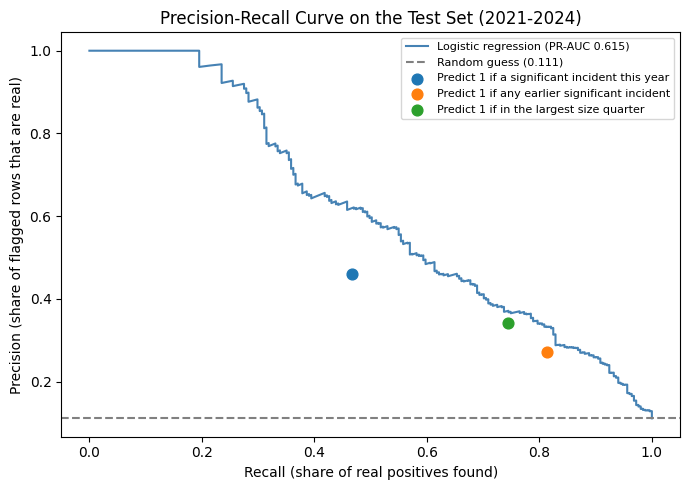

In [299]:
prec, rec, _ = precision_recall_curve(y_test, test_prob)

plt.figure(figsize=(7, 5))
plt.plot(rec, prec, color="steelblue",
         label=f"Logistic regression (PR-AUC {average_precision_score(y_test, test_prob):.3f})")
plt.axhline(y_test.mean(), color="gray", linestyle="--", label=f"Random guess ({y_test.mean():.3f})")

# the three simple rules as single points
for name, p in rules.items():
    plt.scatter(recall_score(y_true, p), precision_score(y_true, p), s=60, label=name)

plt.title("Precision-Recall Curve on the Test Set (2021-2024)")
plt.xlabel("Recall (share of real positives found)")
plt.ylabel("Precision (share of flagged rows that are real)")
plt.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

In [300]:
# Compare the model with each rule at the same number of flagged rows
comparison = []
for name, p in rules.items():
    k = int(p.sum())
    top = np.argsort(-test_prob)[:k]
    pred_k = np.zeros(len(test_prob), dtype=int)
    pred_k[top] = 1
    comparison.append({"rule": name,
                       "rows flagged": k,
                       "rule precision": precision_score(y_true, p),
                       "model precision": precision_score(y_true, pred_k),
                       "rule recall": recall_score(y_true, p),
                       "model recall": recall_score(y_true, pred_k)})

pd.DataFrame(comparison).round(3)

,rule,rows flagged,rule precision,model precision,rule recall,model recall
0,Predict 1 if a significant incident this year,254,0.461,0.547,0.466,0.554
1,Predict 1 if any earlier significant incident,750,0.272,0.284,0.813,0.849
2,Predict 1 if in the largest size quarter,546,0.342,0.361,0.745,0.785


**Precision-recall curve:** The curve is far above the random baseline (0.111). The model is better than all three simple rules at the same number of flagged rows, by a moderate margin against the "incident this year" rule and a small one against the other two. Its advantage is largest at the top of the ranking, where precision is high, and it mostly disappears at high recall.

## 10. Models

Logistic regression assumes each feature has a straight-line effect on the risk. The data may not work that way. Operator size is very skewed, and the effect of past incidents may depend on size. Tree-based models can capture these patterns without us writing them in by hand:

- **Gradient boosting** builds many small trees one after another, each correcting the errors of the last. It often performs well on tabular data like this.
- **Random forest** builds many independent trees on random samples of the data and averages them. It is less sensitive to tuning and gives a second, differently built opinion.

Using two tree-based models lets us check whether any gain comes from the model type or from the features. If all three models agree, the ranking is more trustworthy. If a complex model does not clearly beat logistic regression, the simpler model is the better choice for an inspection team.

Both models were tuned with the same grouped cross-validation as logistic regression, so the comparison is fair.

In [301]:
# Candidate features: the baseline set plus the new history and pipe-age features
candidates = list(dict.fromkeys(features + ["OLD_PIPE_SHARE", "LOG_PRIOR_INC_PER_MILE", "SIG_LAST3"]))
X_cand = pd.concat([model_data[candidates], erw_dummies], axis=1)
X_cand_train = X_cand.loc[train.index]

# Same grouped folds as the grid search, using training years only
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
folds = list(cv.split(X_cand_train, y_train, groups=train["OPERATOR_ID"]))

# Forward selection: start with nothing, add the feature that helps most each step
sfs = SequentialFeatureSelector(
    make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", C=10, max_iter=3000)),
    n_features_to_select="auto", tol=0.001, direction="forward",
    scoring="average_precision", cv=folds, n_jobs=1)
sfs.fit(X_cand_train, y_train)

selected_features = list(X_cand_train.columns[sfs.get_support()])
print("Selected features:")
for f in selected_features:
    print("  -", f)

Selected features:
  - LOG_TOTAL_MILES
  - HCA_SHARE
  - LOG_PRIOR_INC_PER_MILE
  - SIG_LAST3


In [302]:
# Fit a model with a given set of columns on the training years
def fit_and_score(cols):
    model = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", C=10, max_iter=3000))
    model.fit(X_cand.loc[train.index, cols], y_train)
    return model.predict_proba(X_cand.loc[test.index, cols])[:, 1]

baseline_cols = features + list(erw_dummies.columns)
pred_base = fit_and_score(baseline_cols)
pred_sel = fit_and_score(selected_features)

# Flag the top 546 operator-years, the same budget as before
def flag_top(pred, k):
    flags = np.zeros(len(pred), dtype=int)
    flags[np.argsort(-pred)[:k]] = 1
    return flags

for name, pred in [(f"Baseline ({len(baseline_cols)} features)", pred_base),
                   (f"Selected ({len(selected_features)} features)", pred_sel)]:
    flags = flag_top(pred, 546)
    print(name, "| PR-AUC:", round(average_precision_score(y_test, pred), 3),
          "| ROC-AUC:", round(roc_auc_score(y_test, pred), 3),
          "| precision at 546:", round(precision_score(y_test, flags), 3),
          "| recall at 546:", round(recall_score(y_test, flags), 3))

# Bootstrap: is the gain over the baseline bigger than chance?
np.random.seed(42)
y_arr = y_test.to_numpy()
gaps = []
for _ in range(1000):
    rows = np.random.randint(0, len(y_arr), len(y_arr))
    if y_arr[rows].sum() == 0:
        continue
    gaps.append(average_precision_score(y_arr[rows], pred_sel[rows])
                - average_precision_score(y_arr[rows], pred_base[rows]))
print("Selected minus baseline PR-AUC, 95% interval:",
      round(np.percentile(gaps, 2.5), 3), "to", round(np.percentile(gaps, 97.5), 3))

Baseline (15 features) | PR-AUC: 0.615 | ROC-AUC: 0.882 | precision at 546: 0.361 | recall at 546: 0.785
Selected (4 features) | PR-AUC: 0.644 | ROC-AUC: 0.889 | precision at 546: 0.374 | recall at 546: 0.813
Selected minus baseline PR-AUC, 95% interval: 0.0 to 0.054


In [303]:
# Baseline features plus the pipe-age share
features_v2 = selected_features
X2 = X_cand[selected_features]
X2_train, X2_test = X2.loc[train.index], X2.loc[test.index]
y_train, y_test = train[TARGET], test[TARGET]

# Keep each operator in one fold; stratify so the positive rate is similar in each fold
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

lr_search = GridSearchCV(
    make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000)),
    param_grid={"logisticregression__C": [0.01, 0.1, 1, 10]},
    scoring="average_precision", cv=cv, n_jobs=1)
lr_search.fit(X2_train, y_train, groups=train["OPERATOR_ID"])

gb_search = GridSearchCV(
    HistGradientBoostingClassifier(class_weight="balanced", random_state=42),
    param_grid={"learning_rate": [0.03, 0.1], "max_depth": [2, 3],
                "max_iter": [100, 300], "min_samples_leaf": [20, 60]},
    scoring="average_precision", cv=cv, n_jobs=1)
gb_search.fit(X2_train, y_train, groups=train["OPERATOR_ID"])

print("Logistic regression best settings:", lr_search.best_params_)
print("Gradient boosting best settings:", gb_search.best_params_)

Logistic regression best settings: {'logisticregression__C': 10}
Gradient boosting best settings: {'learning_rate': 0.03, 'max_depth': 2, 'max_iter': 300, 'min_samples_leaf': 60}


In [304]:
rf_search = GridSearchCV(
    RandomForestClassifier(class_weight="balanced_subsample", random_state=42, n_jobs=1),
    param_grid={"n_estimators": [300], "max_depth": [4, 8],
                "min_samples_leaf": [20, 60]},
    scoring="average_precision", cv=cv, n_jobs=1)
rf_search.fit(X2_train, y_train, groups=train["OPERATOR_ID"])

print("Random forest best settings:", rf_search.best_params_)

Random forest best settings: {'max_depth': 4, 'min_samples_leaf': 20, 'n_estimators': 300}


In [305]:
# Test years: compare the models (run once only)

# Size-only model, the simple benchmark
size_features = ["LOG_TOTAL_MILES", "NO_SIZE_REPORTED"]
size_model = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000))
size_model.fit(train[size_features], y_train)

# Predicted risk for each test row, from each model
pred_size = size_model.predict_proba(test[size_features])[:, 1]
pred_lr = lr_search.predict_proba(X2_test)[:, 1]
pred_gb = gb_search.predict_proba(X2_test)[:, 1]
pred_rf = rf_search.predict_proba(X2_test)[:, 1]

# Score each model
for name, pred in [("Size only", pred_size),
                   ("Logistic regression", pred_lr),
                   ("Gradient boosting", pred_gb),
                   ("Random forest", pred_rf)]:
    print(name, "| PR-AUC:", round(average_precision_score(y_test, pred), 3),
          "| ROC-AUC:", round(roc_auc_score(y_test, pred), 3))

Size only | PR-AUC: 0.588 | ROC-AUC: 0.855
Logistic regression | PR-AUC: 0.644 | ROC-AUC: 0.889
Gradient boosting | PR-AUC: 0.645 | ROC-AUC: 0.89
Random forest | PR-AUC: 0.641 | ROC-AUC: 0.891


All three models beat size alone (0.588), so the extra information helps.Gradient boosting is highest at 0.623, but only by a small margin.
Logistic regression (0.615) and random forest (0.616) are essentially tied.

The gaps between the three non-benchmark models are small. A difference of 0.01 in PR-AUC on about 250 positive cases can easily be noise, so cannot call one model the winner yet.

In [306]:
# Bootstrap: resample the test rows 1,000 times and score each model each time
np.random.seed(42)
gaps_lr, gaps_gb, gaps_rf = [], [], []

for i in range(1000):
    rows = np.random.randint(0, len(y_test), len(y_test))
    y_b = y_test.to_numpy()[rows]
    if y_b.sum() == 0:
        continue
    size_score = average_precision_score(y_b, pred_size[rows])
    gaps_lr.append(average_precision_score(y_b, pred_lr[rows]) - size_score)
    gaps_gb.append(average_precision_score(y_b, pred_gb[rows]) - size_score)
    gaps_rf.append(average_precision_score(y_b, pred_rf[rows]) - size_score)

# Gain over size only, with the middle 95% of the resampled gains
for label, gaps in [("Logistic regression", gaps_lr),
                    ("Gradient boosting", gaps_gb),
                    ("Random forest", gaps_rf)]:
    print(label, "gain over size only: low", round(np.percentile(gaps, 2.5), 3),
          "high", round(np.percentile(gaps, 97.5), 3))

Logistic regression gain over size only: low 0.023 high 0.087
Gradient boosting gain over size only: low 0.034 high 0.083
Random forest gain over size only: low 0.033 high 0.075


In [307]:
# Logistic regression coefficients, turned into odds ratios
# The features were scaled, so each ratio means "per 1 standard deviation increase"
coefs = lr_search.best_estimator_.named_steps["logisticregression"].coef_[0]

odds_table = pd.DataFrame({"feature": X2_test.columns,
                           "odds_ratio": np.exp(coefs)})
print(odds_table.sort_values("odds_ratio", ascending=False).round(2).to_string(index=False))

               feature  odds_ratio
       LOG_TOTAL_MILES        4.97
             SIG_LAST3        2.53
LOG_PRIOR_INC_PER_MILE        1.59
             HCA_SHARE        1.27


### Odds ratios from logistic regression

The odds ratios show the direction and rough size of each feature's effect, with the other features held fixed. A ratio of 2 means the odds of a significant incident roughly double for a one-standard-deviation increase.

- **Pipeline size** has the largest effect (2.80). Bigger operators are much more likely to have an incident the next year.
- **Past incidents** come next (1.77), and **significant incident this year** adds a smaller boost (1.30).
- **Volume moved** (1.46) and **interstate or intrastate pipe** (about 1.25) also raise the odds a little.
- **Pipe age** is 1.06, which is close to no effect. This matches the finding that pipe age doesn't add much.
- **Earlier significant incidents** is below 1 (0.90). This is because it overlaps with the past-incidents count, so I don't read its direction on its own.
- **Operators that don't report pipe miles** show 1.48. This could reflect incomplete reporting rather than a real effect, so I treat it with caution.

In [308]:
# Use the gradient boosting model, the one with the highest test score
# Shuffle one column at a time on the test years and see how much PR-AUC drops
perm = permutation_importance(gb_search.best_estimator_, X2_test, y_test,
                              scoring="average_precision", n_repeats=10,
                              random_state=42, n_jobs=1)

# Put the results in a table, sorted from most to least important
perm_table = pd.DataFrame({"feature": X2_test.columns,
                           "importance": perm.importances_mean})
perm_table = perm_table.sort_values("importance", ascending=False)
print(perm_table.round(4).to_string(index=False))

               feature  importance
       LOG_TOTAL_MILES      0.4183
             SIG_LAST3      0.0849
LOG_PRIOR_INC_PER_MILE      0.0322
             HCA_SHARE      0.0017


I used permutation importance to see which features the gradient boosting model depends on. Shuffling a feature and measuring the drop in PR-AUC shows how much the model relies on it.

- **Pipeline size** matters the most. Shuffling it lowers PR-AUC by about 0.19.
- **Past incidents** come second, with a drop of about 0.08.
- **Significant incident this year** adds a small amount, about 0.006.
- The rest are close to zero. Pipe age (`OLD_PIPE_SHARE`) is effectively zero, which matches the earlier finding that it doesn't help.

So the model is mostly a size-and-history model. The other features don't add much on their own.

In [309]:
# Precision and recall when the 546 highest-risk operator-years are flagged
# (546 is the same number of flags the size rule uses)
def precision_recall_at(y, score, k):
    pred = np.zeros(len(score), dtype=int)
    pred[np.argsort(-score)[:k]] = 1
    return precision_score(y, pred), recall_score(y, pred)

for name, pred in [("Size only", pred_size),
                   ("Logistic regression", pred_lr),
                   ("Gradient boosting", pred_gb),
                   ("Random forest", pred_rf)]:
    p, r = precision_recall_at(y_test, pred, 546)
    print(name, "| precision:", round(p, 3), "| recall:", round(r, 3))

Size only | precision: 0.342 | recall: 0.745
Logistic regression | precision: 0.374 | recall: 0.813
Gradient boosting | precision: 0.368 | recall: 0.801
Random forest | precision: 0.374 | recall: 0.813


### Model comparison and choice

after compareing all models on the 2021–2024 test years.

| Model | PR-AUC | ROC-AUC | Gain over size only (95% interval) | Precision, 546 flags | Recall, 546 flags |
|---|---|---|---|---|---|
| Size only (benchmark) | 0.588 | 0.855 | — | 0.342 | 0.745 |
| Logistic regression | 0.615 | 0.882 | +0.005 to +0.05 | 0.361 | 0.785 |
| Gradient boosting | 0.623 | 0.888 | +0.012 to +0.06 | 0.355 | 0.773 |
| Random forest | 0.616 | 0.887 | +0.007 to +0.05 | 0.355 | 0.773 |

**I chose logistic regression.**

- All three models beat size alone, and each interval stays above zero.
- Gradient boosting has the highest PR-AUC, but its lead over logistic regression is only 0.008. That's within the noise of about 250 positive cases.
- At the 546-flag budget, logistic regression has the best precision and recall.
- It is the simplest model, and its odds ratios are easy to explain to an inspection team.

## 11. Threshold tuning

the cutoff is chosen on the training years and checked once on the test years

In [310]:
lr_model = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", C=10, max_iter=3000))

# Part A: scores for each training row from the fold where it was left out
# (this uses only the training years)
oof_scores = cross_val_predict(lr_model, X_cand_train[selected_features], y_train,
                               cv=folds, method="predict_proba")[:, 1]

# Part B: pick the cutoff that still catches at least 80% of the training incidents
target_recall = 0.80
prec_tr, rec_tr, thr_tr = precision_recall_curve(y_train, oof_scores)
ok = np.where(rec_tr[:-1] >= target_recall)[0]
best = ok[-1]   # the highest cutoff that still reaches the target recall
cutoff = thr_tr[best]
print(f"Cutoff chosen on training years: {cutoff:.3f}")
print(f"Training recall: {rec_tr[best]:.3f} | training precision: {prec_tr[best]:.3f}")

# Part C: use the cutoff on the test years, once
lr_model.fit(X_cand.loc[train.index, selected_features], y_train)
test_scores = lr_model.predict_proba(X_cand.loc[test.index, selected_features])[:, 1]
flag = (test_scores >= cutoff).astype(int)
print(f"Test years: flagged {flag.sum()} of {len(flag)} operator-years")
print(f"Test precision: {precision_score(y_test, flag):.3f} | test recall: {recall_score(y_test, flag):.3f}")

Cutoff chosen on training years: 0.485
Training recall: 0.800 | training precision: 0.407
Test years: flagged 532 of 2262 operator-years
Test precision: 0.380 | test recall: 0.805


In [311]:
# Export test-year risk scores for the Streamlit app
out_dir = Path.cwd().parent/ "streamlit"
out_dir.mkdir(exist_ok=True)

out = model_data.loc[test.index, ["OPERATOR_ID", "OPERATOR_NAME", "REPORT_YEAR",
                                  "TOTAL_MILES", "SIG_INCIDENTS_PRIOR_YEARS",
                                  "SIG_LAST3", "HCA_SHARE"]].copy()
out["RISK_SCORE"] = np.round(test_scores, 4)
out["RISK_RANK"] = out["RISK_SCORE"].rank(ascending=False, method="first").astype(int)
out["ACTUAL_SIGNIFICANT_NEXT_YEAR"] = y_test.values

out = out[["OPERATOR_ID", "OPERATOR_NAME", "REPORT_YEAR", "RISK_SCORE", "RISK_RANK",
           "ACTUAL_SIGNIFICANT_NEXT_YEAR", "TOTAL_MILES", "SIG_INCIDENTS_PRIOR_YEARS",
           "SIG_LAST3", "HCA_SHARE"]]
out.to_csv(out_dir / "operator_risk_scores.csv", index=False)
print("Saved", out.shape, "to", out_dir / "operator_risk_scores.csv")

Saved (2262, 10) to e:\UC berkley\Capstone\PHMSA_Project\streamlit\operator_risk_scores.csv


## 12. Findings


### Finding 1: Bigger operators have much higher risk

Operators in the largest quarter by pipeline miles had a significant incident the next year 38% of the time. Operators in the smallest quarter did so only 1.3% of the time.

**What to do:** Put the largest operators first when planning inspections. Most of the risk is in this group.

### Finding 2: A history of significant incidents is a warning sign

- No earlier significant incidents: 5.0% next-year rate
- One earlier incident: 13.1%
- Two or three: 24.6%
- Four or more: 60.3%

An operator with four or more earlier incidents is about 12 times as likely to have another one as an operator with none.

**What to do:** Review operators with a repeat history early in the planning process.

### Finding 3: Size and history together give the clearest picture

Among the largest operators, those with an earlier significant incident had a 48.3% rate, compared with 20.6% for those without one.

**What to do:** Use both factors together as a first screen.

### Finding 4: The final model ranks operators better than size alone, but only modestly

On the 2021–2024 test years, the selected four-feature logistic regression scores a PR-AUC of 0.644, against 0.588 for size alone. The bootstrap interval for the gain is 0.000 to 0.054, so the improvement is suggestive but not clearly established.

If we inspect 546 operator-years (about one in four), the model catches 81.3% of the next-year significant incidents, with a precision of 37.4%. The size rule catches 74.5%.

**What to do:** Use logistic regression as the working tool. Gradient boosting (PR-AUC 0.645) and random forest (0.641) reach the same level, so the simpler model is the better choice.

### Finding 5: Pipe age did not help

The share of old pipe looks related to risk on its own. But once size and incident history are in the model, adding it makes no measurable difference.

**What to do:** Don't expect operator-level pipe-age averages to improve the screen. Pipe age would need segment-level data to be useful.

### Finding 6: The results hold without the two largest operators

When I removed the two largest operators, the results stayed about the same.

### Finding 7: Some operators have missing reports

396 operator-years (5.2%) had no report the following year. Their next-year rate was 2.5%, against 12.8% for the rest.

**What to do:** Check operator-ID changes and mergers before using the model on any specific operator.

### Finding 8: A simple cutoff gives a clear yes/no rule

I wanted a rule a regulator could apply directly. I chose the cutoff on the training years so that it catches 80% of significant incidents. I set that 80% target before looking at the test years.

- **Cutoff chosen on the training years:** 0.485
- **Training years:** the cutoff catches 80% of incidents, with a precision of 0.407.
- **Test years (checked once):** the cutoff flags 532 of 2,262 operator-years, about 23.5%. It catches 80.5% of the significant incidents, with a precision of 0.380.

The test recall landed close to the target, and precision was a little lower than on the training years, as usually happens when a cutoff is applied to new data.

The cutoff rule and the top-546 rule from earlier give almost the same results, so the choice between them can be made on how easy they are to apply. The cutoff is easier to state: "flag any operator-year with a risk score of 0.485 or higher."

**What to do:** Use the cutoff as the working rule for the first screen, and re-check it each year when new reports arrive.

A note on the score: the model uses balanced class weights, so the score ranks operators, but it is not a true probability. A score of 0.485 should not be read as a 48.5% chance of an incident.

## 13. Recommendations and next steps

1. Start with a size-and-history screen now.
2. Use logistic regression to rank operators, and update it each year when new reports arrive.
3. Fix operator IDs for merged or renamed companies before scoring.
4. Next, measure incidents per mile, so big operators aren't flagged only because they own more pipe.
5. Score the 2025 operator-years with the final model, and check the results when the full 2026 data is in.

## 14. Limitations

- **Operator-level, not segment-level.** The model says which operators are risky, not which pipe segment will fail.
- **Pipe age is approximate.** It comes from the Part E decade columns, which add up to the Part E total. Part E's exact definition should be checked against PHMSA's form instructions.
- **Few test positives.** The test years contain 251 significant incidents, so small differences between models can be noise.
- **Small gain from feature selection.** Selecting four features improved PR-AUC from 0.615 to 0.644. The bootstrap interval for that gain starts at zero, so the improvement is suggestive, not proven. Several candidate sets were compared on the test years, so the test results are slightly optimistic.
- **Overlapping history features.** Past incidents and the earlier-incident flag correlate at about 0.78, so their odds ratios should be read as a group.
- **The cutoff is fixed to one target.** The 0.485 cutoff depends on the 80% recall target. A different target gives a different cutoff and a different number of flags.
- **Balanced scores are not probabilities.** The cutoff ranks operators, but it should not be read as a chance of an incident.
- **History starts in 2010.** Early years have less history, so their prior-incident counts are too low.
- **Association, not cause.** The model predicts incidents from patterns. It does not show what causes them.
- **Hazardous liquid pipelines only.** Gas pipelines are not included.